# Gain factors from recorded / predicted ratios on the clean emitter set (4-fish, Kaden masks)

**Sets.** The clean emitter set of `EOD_clean_emitter_set_4fish_kaden.ipynb` (good masks, emitter ≥ 10 cm from the others,
lowest shape L2, its 2 nearest pairs = the 2 loudest recorded pairs with its model sign, other fish ≤ ½ its predicted |v| there):
- **93**: the hand-inspection picks (3 per fish × nearest pair);
- **1365**: every EOD that passes.

**Models** (both on my mask midline of the EOD's own frame, no normalisation):
- **Denis**: his analytic pipeline (point currents along the midline, one sink, first-order wall reflections), `predicted_ptp`
  in his arbitrary units; recorded = his recorded peak-to-peak, `recorded_ptp` (signed), from `denis_predicted_voltages.npz`;
- **mine**: my BEM model, unit current at the tail tip, `mine_unit_current` (× −1 sign convention of the shape assignment);
  recorded = the main-phase pattern `recorded_peak` (all 10 pairs at the sample of the largest |V|), from `predicted_voltages.npz`.

**Ratios.** For each EOD, the 3 pairs with the largest recorded |amplitude| (each pipeline's own recorded measure), and on each
the gain $g = |V_\text{rec}| / |V_\text{pred}|$ of the emitter. Every (EOD, pair) ratio is one data point; the sign agreement of
recorded and predicted on these pairs is reported separately.

**Ratios left out.** A ratio is undefined where the prediction crosses zero: on the 3rd loudest pair (mostly pairs 9 and 10)
the emitter's prediction can be ~0 while the recording is not, giving ratios up to ~36 000 that alone set a least-squares
line. Left out: ratios where the predicted sign differs from the recorded one, or where |predicted| < 5% of the emitter's
largest predicted |v| over the 10 pairs. All fits use the remaining ratios; the counts are printed below.

**Per fish × per pair gains.** (i) the median ratio per fish and pair; (ii) a fish × pair decomposition
$\log g = \log a_f + \log b_p + \varepsilon$ (least squares on the log ratios, pair factors with geometric mean 1), so that each fish
factor $a_f$ is not biased by which pairs that fish happened to be loud on.

**Length.** Fish length L = 90th percentile of the mask midline length over the five videos (A 15.65, B 13.10, C 9.82,
D 8.51 cm). Fits of the gain against L:
- linear $g = s L + c$ (least squares on the ratios);
- power law $g = k L^e$ (least squares on log g vs log L); e = 1 with c = 0 means proportional to length;
- the same two fits through the 4 fish factors $a_f$.

95% intervals: 2000 bootstrap resamples of EODs (all 3 ratios of an EOD stay together).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
SRC = f'{BASE}/clean_emitter_set'
OUT = f'{SRC}/gain_ratios'; os.makedirs(OUT, exist_ok=True)
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}
NTOP, NBOOT = 3, 2000
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
SETS = {'93 picked': pd.read_csv(f'{SRC}/clean_emitter_set.csv'), '1365 passing': pd.read_csv(f'{SRC}/clean_emitter_all_passing.csv')}
RAW = {}
for t in sorted(SETS['1365 passing'].video.unique()):
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz'); d = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    assert (z['frame'] == d['frame']).all()
    RAW[t] = dict(mine=(z['recorded_peak'], z['mine_unit_current']), Denis=(d['recorded_ptp'], d['predicted_ptp']))

def ratios(S, model):
    out = []
    for k, r in enumerate(S.itertuples()):
        Rv, Mv = RAW[r.video][model]; rec = Rv[r.row]; pred = Mv[r.row, LET.index(r.fish)]
        top = np.argsort(-np.abs(rec))[:NTOP]
        for rank, p in enumerate(top):
            out.append(dict(eod=k, video=r.video, row=r.row, Frame=r.Frame, fish=r.fish, L_cm=L_CM[r.fish], pair=p + 1, rank=rank + 1,
                            rec=rec[p], pred=pred[p], gain=abs(rec[p]) / abs(pred[p]), same_sign=np.sign(rec[p]) == np.sign(pred[p]),
                            pred_frac=abs(pred[p]) / np.abs(pred).max()))
    return pd.DataFrame(out)

MIN_FRAC = 0.05
ALL = {(s, m): ratios(S, m) for s, S in SETS.items() for m in ('Denis', 'mine')}
DATA = {}
for (s, m), d in ALL.items():
    d['kept'] = d.same_sign & (d.pred_frac >= MIN_FRAC)
    d.to_csv(f'{OUT}/ratios_{m}_{s.split()[0]}.csv', index=False)
    DATA[(s, m)] = d[d.kept].reset_index(drop=True)
    print(f'{s:>13}, {m:>5}: {d.eod.nunique()} EODs, {len(d)} ratios; same sign {d.same_sign.mean() * 100:.1f}% (rank 1 / 2 / 3: '
          + ' / '.join(f'{d[d["rank"] == k].same_sign.mean() * 100:.0f}%' for k in (1, 2, 3)) + f'); '
          f'left out: {(~d.same_sign).sum()} wrong sign, {(d.same_sign & (d.pred_frac < MIN_FRAC)).sum()} |pred| < {MIN_FRAC:.0%} of max; '
          f'kept {d.kept.sum()}; largest ratio / median before {d.gain.max() / d.gain.median():.0f}, after {DATA[(s, m)].gain.max() / DATA[(s, m)].gain.median():.1f}')

    93 picked, Denis: 93 EODs, 279 ratios; same sign 98.6% (rank 1 / 2 / 3: 100% / 99% / 97%); left out: 4 wrong sign, 3 |pred| < 5% of max; kept 272; largest ratio / median before 77, after 2.7
    93 picked,  mine: 93 EODs, 279 ratios; same sign 99.3% (rank 1 / 2 / 3: 100% / 100% / 98%); left out: 2 wrong sign, 1 |pred| < 5% of max; kept 276; largest ratio / median before 220, after 3.2
 1365 passing, Denis: 1365 EODs, 4095 ratios; same sign 99.6% (rank 1 / 2 / 3: 100% / 100% / 99%); left out: 18 wrong sign, 14 |pred| < 5% of max; kept 4063; largest ratio / median before 8252023, after 9.4


 1365 passing,  mine: 1365 EODs, 4095 ratios; same sign 99.7% (rank 1 / 2 / 3: 100% / 100% / 99%); left out: 14 wrong sign, 3 |pred| < 5% of max; kept 4078; largest ratio / median before 276, after 11.9


## Per fish × per pair gains (median ratio; n in brackets)

In [2]:
def two_way(d):
    '''log g = log a_f + log b_p, least squares; pair factors geometric mean 1. Returns a (4,), b (10,) with NaN for unseen.'''
    d = d[np.isfinite(d.gain) & (d.gain > 0)]
    fi = d.fish.map(LET.index).to_numpy(); pi = d.pair.to_numpy() - 1
    seen_p = np.unique(pi); X = np.zeros((len(d), 4 + len(seen_p)))
    X[np.arange(len(d)), fi] = 1; X[np.arange(len(d)), 4 + np.searchsorted(seen_p, pi)] = 1
    A = np.r_[X, np.r_[np.zeros(4), np.ones(len(seen_p))][None]]                                 # extra row: sum of log b = 0
    y = np.r_[np.log(d.gain.to_numpy()), 0]
    sol = np.linalg.lstsq(A, y, rcond=None)[0]
    a = np.exp(sol[:4]); a[[not (fi == j).any() for j in range(4)]] = np.nan
    b = np.full(10, np.nan); b[seen_p] = np.exp(sol[4:])
    return a, b

TABLES, TW = {}, {}
for (s, m), d in DATA.items():
    med = d.pivot_table(index='fish', columns='pair', values='gain', aggfunc='median')
    n = d.pivot_table(index='fish', columns='pair', values='gain', aggfunc='size').reindex_like(med)
    a, b = two_way(d); TW[(s, m)] = (a, b)
    T = med.copy(); T['fish factor a_f (two-way)'] = a; T['median of all its ratios'] = d.groupby('fish').gain.median()
    TABLES[(s, m)] = T
    T.to_csv(f'{OUT}/gain_fish_x_pair_{m}_{s.split()[0]}.csv')
    show = med.map(lambda v: f'{v:.3g}') + n.map(lambda v: '' if np.isnan(v) else f' ({int(v)})')
    show['a_f (two-way)'] = [f'{v:.3g}' for v in a]
    show.loc['b_p (two-way)'] = [f'{v:.2f}' if np.isfinite(v) else '' for v in b[med.columns - 1]] + ['']
    print(f'\n{s}, {m} model'); display(show.fillna(''))


93 picked, Denis model


pair,1,2,3,4,5,6,7,8,9,10,a_f (two-way)
fish,,,,,,,,,,,
A,0.00574 (5),0.00466 (5),0.00482 (6),0.0065 (4),0.0077 (6),0.00832 (8),0.00712 (9),0.00777 (8),0.00654 (8),0.00997 (18),0.0065
B,0.004 (5),0.00383 (7),0.00314 (9),0.0068 (2),nan,0.00535 (6),0.00458 (8),0.00464 (6),0.00462 (6),0.00528 (15),0.0045
C,0.00387 (2),0.00435 (6),0.00512 (10),0.00516 (5),0.00617 (6),0.00676 (9),0.00701 (8),0.00695 (6),0.00839 (8),0.00841 (18),0.00607
D,0.00287 (4),0.00293 (1),0.0047 (5),0.00419 (5),0.0028 (1),0.0073 (4),0.0046 (9),0.0041 (8),0.00368 (7),0.0062 (9),0.00423
b_p (two-way),0.78,0.75,0.88,0.95,1.08,1.27,1.07,0.99,1.13,1.24,



93 picked, mine model


pair,1,2,3,4,5,6,7,8,9,10,a_f (two-way)
fish,,,,,,,,,,,
A,0.388 (5),0.285 (5),0.299 (6),0.415 (4),0.641 (6),0.68 (8),0.574 (9),0.588 (8),0.398 (9),0.464 (18),0.452
B,0.297 (5),0.298 (7),0.269 (9),0.662 (2),nan,0.38 (6),0.39 (8),0.374 (7),0.271 (6),0.357 (15),0.357
C,0.373 (2),0.361 (6),0.408 (10),0.399 (5),0.537 (6),0.527 (9),0.537 (8),0.56 (6),0.425 (8),0.431 (18),0.456
D,0.228 (4),0.277 (1),0.406 (5),0.268 (5),0.301 (1),0.832 (4),0.419 (9),0.328 (8),0.28 (7),0.363 (11),0.35
b_p (two-way),0.85,0.78,0.88,0.98,1.27,1.32,1.20,1.04,0.86,0.97,



1365 passing, Denis model


pair,1,2,3,4,5,6,7,8,9,10,a_f (two-way)
fish,,,,,,,,,,,
A,0.00591 (25),0.00424 (20),0.00475 (22),0.00633 (19),0.00815 (151),0.00803 (211),0.00729 (179),0.00785 (125),0.00858 (102),0.011 (272),0.00753
B,0.0036 (85),0.00349 (560),0.00254 (565),0.00612 (3),nan,0.00549 (57),0.00454 (70),0.00479 (101),0.00441 (86),0.00266 (632),0.00344
C,0.0049 (12),0.0042 (51),0.0039 (62),0.00559 (12),0.00671 (17),0.00778 (46),0.00699 (56),0.00702 (39),0.00859 (35),0.0063 (111),0.00594
D,0.00287 (8),0.00293 (1),0.00453 (19),0.00429 (22),0.00303 (4),0.0065 (18),0.0049 (85),0.00482 (71),0.00456 (24),0.00783 (85),0.00503
b_p (two-way),0.96,0.97,0.73,0.87,1.13,1.16,1.00,1.07,1.19,1.01,



1365 passing, mine model


pair,1,2,3,4,5,6,7,8,9,10,a_f (two-way)
fish,,,,,,,,,,,
A,0.366 (25),0.271 (20),0.286 (22),0.371 (19),0.613 (150),0.561 (211),0.536 (181),0.581 (125),0.386 (103),0.483 (272),0.473
B,0.297 (86),0.283 (560),0.213 (566),0.381 (3),nan,0.389 (57),0.335 (70),0.363 (102),0.313 (89),0.281 (633),0.315
C,0.394 (12),0.314 (51),0.324 (62),0.506 (12),0.556 (17),0.581 (46),0.505 (57),0.54 (39),0.41 (35),0.394 (112),0.449
D,0.282 (8),0.277 (1),0.406 (19),0.315 (22),0.339 (4),0.823 (18),0.418 (85),0.355 (73),0.277 (26),0.353 (85),0.359
b_p (two-way),0.95,0.84,0.69,0.92,1.35,1.31,1.19,1.15,0.88,0.91,


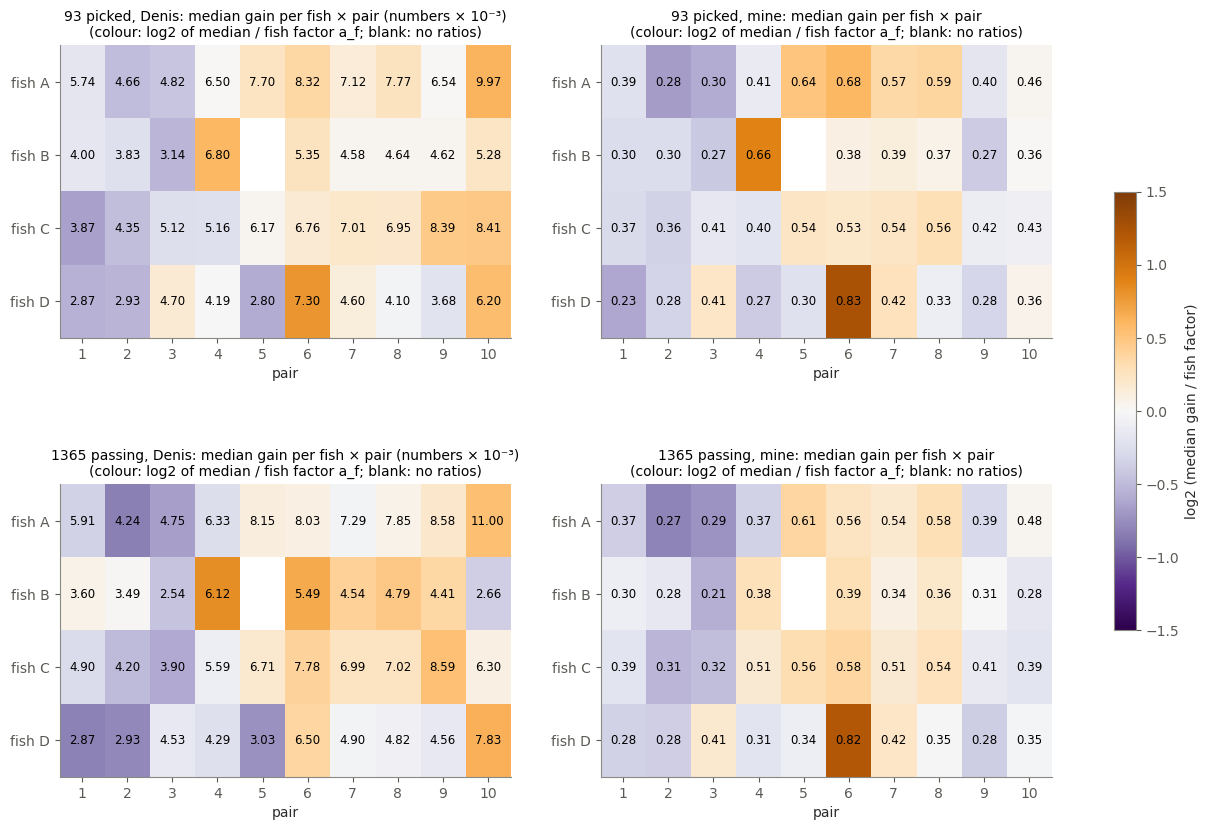

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(16, 9.5), gridspec_kw=dict(hspace=0.5))
for ax, ((s, m), T) in zip(axs.ravel(), TABLES.items()):
    med = T[[c for c in T.columns if isinstance(c, (int, np.integer))]].reindex(columns=range(1, 11))
    rel = med / T['fish factor a_f (two-way)'].to_numpy()[:, None]                 # per-pair gain relative to the fish factor
    im = ax.imshow(np.log2(rel.to_numpy(float)), cmap='PuOr_r', vmin=-1.5, vmax=1.5, aspect='auto')
    for i in range(4):
        for j in range(10):
            v = med.iloc[i, j]
            if np.isfinite(v): ax.text(j, i, f'{v * (1000 if m == "Denis" else 1):.2f}', ha='center', va='center', fontsize=8.5)
    ax.set(xticks=range(10), xticklabels=range(1, 11), yticks=range(4), yticklabels=[f'fish {f}' for f in LET], xlabel='pair')
    unit = ' (numbers × 10⁻³)' if m == 'Denis' else ''
    ax.set_title(f'{s}, {m}: median gain per fish × pair{unit}\n(colour: log2 of median / fish factor a_f; blank: no ratios)', fontsize=10); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.6, label='log2 (median gain / fish factor)')
fig.savefig(f'{OUT}/gain_fish_x_pair_heatmaps.png', dpi=110, bbox_inches='tight'); plt.show()

## Does the gain scale with fish length?

In [4]:
def fits(L, g):
    ok = np.isfinite(g) & (g > 0)
    s, c = np.polyfit(L[ok], g[ok], 1); e, lk = np.polyfit(np.log(L[ok]), np.log(g[ok]), 1)
    return s, c, e, np.exp(lk)

def boot(d, rng):
    eods = d.eod.unique(); grp = {k: v for k, v in d.groupby('eod').indices.items()}
    res = []
    for _ in range(NBOOT):
        idx = np.concatenate([grp[k] for k in rng.choice(eods, len(eods))]); b = d.iloc[idx]
        if b.fish.nunique() < 2: continue
        a, _ = two_way(b); Lf = np.array([L_CM[f] for f in LET]); ok = np.isfinite(a)
        res.append(np.r_[fits(b.L_cm.to_numpy(), b.gain.to_numpy()), fits(Lf[ok], a[ok]) if ok.sum() >= 2 else [np.nan] * 4])
    return np.array(res)

rng = np.random.default_rng(0); rows = []; FITS = {}
Lf = np.array([L_CM[f] for f in LET])
for (s, m), d in DATA.items():
    a, _ = TW[(s, m)]; ok = np.isfinite(a)
    est = np.r_[fits(d.L_cm.to_numpy(), d.gain.to_numpy()), fits(Lf[ok], a[ok])]
    B = boot(d, rng); lo, hi = np.nanpercentile(B, [2.5, 97.5], axis=0); FITS[(s, m)] = est
    for k, (src, nm) in enumerate([('all ratios', 'slope s (per cm)'), ('all ratios', 'intercept c'), ('all ratios', 'exponent e'), ('all ratios', 'k'),
                                   ('fish factors a_f', 'slope s (per cm)'), ('fish factors a_f', 'intercept c'), ('fish factors a_f', 'exponent e'), ('fish factors a_f', 'k')]):
        rows.append(dict(set=s, model=m, fit_to=src, parameter=nm, estimate=est[k], ci_low=lo[k], ci_high=hi[k]))
FT = pd.DataFrame(rows); FT.to_csv(f'{OUT}/length_fits.csv', index=False)
show = FT.assign(value=[f'{e:.3g}  [{l:.3g}, {h:.3g}]' for e, l, h in zip(FT.estimate, FT.ci_low, FT.ci_high)])
display(show.pivot_table(index=['set', 'model', 'fit_to'], columns='parameter', values='value', aggfunc='first')[
    ['slope s (per cm)', 'intercept c', 'exponent e', 'k']])

parameter                                          slope s (per cm)  \
set          model fit_to                                             
1365 passing Denis all ratios        0.000376  [0.000303, 0.000448]   
                   fish factors a_f  0.000185  [0.000144, 0.000225]   
             mine  all ratios              0.0175  [0.0126, 0.0225]   
                   fish factors a_f      0.00669  [0.00408, 0.0093]   
93 picked    Denis all ratios        0.000178  [2.75e-05, 0.000309]   
                   fish factors a_f  0.000179  [6.57e-05, 0.000285]   
             mine  all ratios           0.00415  [-0.00717, 0.0149]   
                   fish factors a_f     0.00632  [-0.00231, 0.0143]   

parameter                                               intercept c  \
set          model fit_to                                             
1365 passing Denis all ratios        0.000392  [-0.000548, 0.00133]   
                   fish factors a_f     0.00331  [0.00278, 0.00383]   
             mine  all ratios                0.161  [0.0943, 0.224]   
                   fish factors a_f            0.32  [0.286, 0.356]   
93 picked    Denis all ratios            0.00404  [0.00243, 0.0058]   
                   fish factors a_f      0.00321  [0.00198, 0.0046]   
             mine  all ratios                 0.392  [0.258, 0.539]   
                   fish factors a_f             0.33  [0.23, 0.439]   

parameter                                         exponent e  \
set          model fit_to                                      
1365 passing Denis all ratios          0.479  [0.337, 0.619]   
                   fish factors a_f    0.216  [0.136, 0.299]   
             mine  all ratios          0.313  [0.197, 0.431]   
                   fish factors a_f   0.152  [0.0738, 0.232]   
93 picked    Denis all ratios         0.354  [0.0459, 0.634]   
                   fish factors a_f    0.388  [0.129, 0.638]   
             mine  all ratios          0.151  [-0.15, 0.441]   
                   fish factors a_f  0.185  [-0.0818, 0.448]   

parameter                                                       k  
set          model fit_to                                          
1365 passing Denis all ratios        0.00134  [0.000937, 0.00192]  
                   fish factors a_f   0.00311  [0.00252, 0.00382]  
             mine  all ratios                0.157  [0.116, 0.21]  
                   fish factors a_f         0.272  [0.221, 0.333]  
93 picked    Denis all ratios           0.00236  [0.00118, 0.005]  
                   fish factors a_f    0.00203  [0.00109, 0.0039]  
             mine  all ratios               0.281  [0.135, 0.587]  
                   fish factors a_f         0.255  [0.131, 0.492]

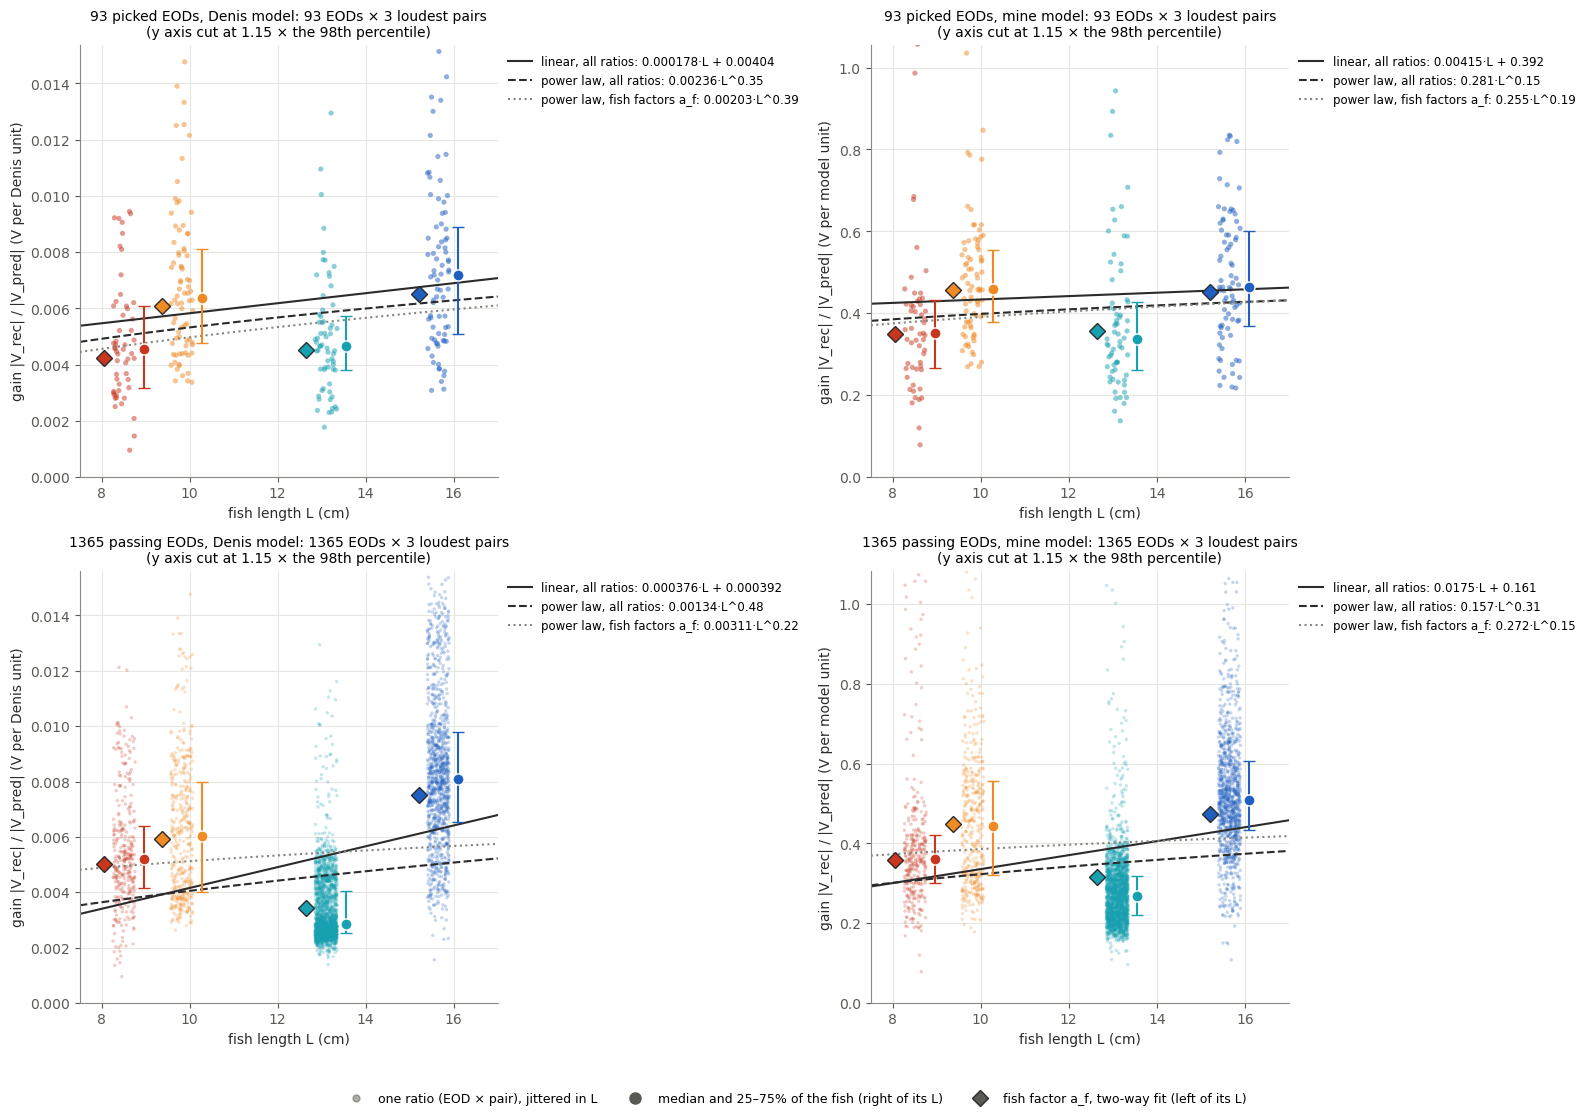

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(16, 11))
xs = np.linspace(7.5, 17, 100); jit = np.random.default_rng(1)
for ax, ((s, m), d) in zip(axs.ravel(), DATA.items()):
    sl, c, e, k, sl_f, c_f, e_f, k_f = FITS[(s, m)]; a, _ = TW[(s, m)]
    for j, f in enumerate(LET):
        g = d[d.fish == f]
        if not len(g): continue
        ax.scatter(g.L_cm + jit.uniform(-0.25, 0.25, len(g)), g.gain, s=6 if len(d) > 1000 else 14, alpha=0.25 if len(d) > 1000 else 0.5,
                   color=FISH_COL[f], edgecolor='none', zorder=2)
        q = g.gain.quantile([0.25, 0.5, 0.75]).to_numpy()
        ax.errorbar(L_CM[f] + 0.45, q[1], yerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt='o', ms=8, color=FISH_COL[f], mec='white', capsize=4, zorder=4)
        ax.plot(L_CM[f] - 0.45, a[j], 'D', ms=8, color=FISH_COL[f], mec='#2b2b2b', zorder=4)
    ax.plot(xs, sl * xs + c, color='#2b2b2b', lw=1.5, label=f'linear, all ratios: {sl:.3g}·L {"+" if c >= 0 else "−"} {abs(c):.3g}')
    ax.plot(xs, k * xs ** e, color='#2b2b2b', lw=1.5, ls='--', label=f'power law, all ratios: {k:.3g}·L^{e:.2f}')
    ax.plot(xs, k_f * xs ** e_f, color='#85857F', lw=1.5, ls=':', label=f'power law, fish factors a_f: {k_f:.3g}·L^{e_f:.2f}')
    top = np.nanpercentile(d.gain, 98) * 1.15
    ax.set(xlim=(7.5, 17), ylim=(0, top), xlabel='fish length L (cm)',
           ylabel=f'gain |V_rec| / |V_pred| ({"V per Denis unit" if m == "Denis" else "V per model unit"})')
    ax.set_title(f'{s} EODs, {m} model: {d.eod.nunique()} EODs × {NTOP} loudest pairs\n(y axis cut at 1.15 × the 98th percentile)', fontsize=10)
    ax.legend(frameon=False, fontsize=8.5, loc='upper left', bbox_to_anchor=(1.0, 1.0))
h = [Line2D([], [], marker='o', ls='', ms=5, color='#5a5a55', alpha=0.5, label='one ratio (EOD × pair), jittered in L'),
     Line2D([], [], marker='o', ls='', ms=8, color='#5a5a55', label='median and 25–75% of the fish (right of its L)'),
     Line2D([], [], marker='D', ls='', ms=8, color='#5a5a55', mec='#2b2b2b', label='fish factor a_f, two-way fit (left of its L)')]
fig.legend(handles=h, frameon=False, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(f'{OUT}/gain_vs_length.png', dpi=110, bbox_inches='tight'); plt.show()